# 대출 승인 여부 예측: 데이터 분석 및 머신러닝 보고서용 노트북

## 분석 목표
대출 신청자의 특성을 바탕으로 `Loan_Status`(승인 Y / 거절 N)를 분류한다. 이 노트북은 단순 모델 학습에서 끝나지 않고, **데이터 품질 확인 → 탐색적 데이터 분석(EDA) → 전처리 설계 → 여러 모델 비교 → 테스트 데이터 평가 → 변수 중요도 해석** 순서로 분석 근거를 남긴다.

> **해석 주의:** 이 데이터는 교육용 예제이며 표본은 614건이다. 모델 성능은 실제 금융 심사에 사용할 수 있다는 증거가 아니며, 관찰된 연관성은 인과관계를 의미하지 않는다.

## 1. 라이브러리 및 경로 설정

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "dataset").exists() and (ROOT.parent / "dataset").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "train_u6lujuX_CVtuZ9i.csv"
MODEL_DIR = ROOT / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", rc={"font.family": "Malgun Gothic"})
pd.set_option("display.max_columns", 50)

# 그래프·표 표시용 한글 변수명 (원본 데이터와 모델 입력 열 이름은 변경하지 않음)
FEATURE_LABELS = {
    "ApplicantIncome": "신청자 소득",
    "CoapplicantIncome": "공동 신청자 소득",
    "LoanAmount": "대출 금액",
    "Loan_Amount_Term": "대출 기간",
    "Credit_History": "신용 이력",
    "Gender": "성별",
    "Married": "혼인 여부",
    "Dependents": "부양가족 수",
    "Education": "교육 수준",
    "Self_Employed": "자영업 여부",
    "Property_Area": "부동산 지역",
    "Loan_Status": "대출 승인 여부",
    "Loan_ID": "대출 신청 식별번호",
}
STATUS_LABELS = {"Y": "승인", "N": "거절"}
CATEGORY_LABELS = {
    "Female": "여성", "Male": "남성", "Yes": "예", "No": "아니오",
    "Graduate": "대졸 이상", "Not Graduate": "비대졸",
    "Rural": "농촌", "Semiurban": "준도시", "Urban": "도시",
    "3+": "3명 이상", "Y": "승인", "N": "거절",
    "0": "0명", "1": "1명", "2": "2명", "0.0": "불량 또는 미확인", "1.0": "양호",
}


## 2. 데이터 불러오기 및 기본 구조

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"데이터 크기: {df_raw.shape[0]:,}행 × {df_raw.shape[1]}열")
display(df_raw.head())

데이터 크기: 614행 × 13열


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
overview = pd.DataFrame({
    "자료형": df_raw.dtypes.astype(str),
    "결측 수": df_raw.isna().sum(),
    "결측 비율(%)": (df_raw.isna().mean() * 100).round(2),
    "고유값 수": df_raw.nunique(dropna=True)
})
display(overview.sort_values("결측 비율(%)", ascending=False))
display(df_raw.describe(include="all").T)

,자료형,결측 수,결측 비율(%),고유값 수
Credit_History,float64,50,8.14,2
Self_Employed,str,32,5.21,2
LoanAmount,float64,22,3.58,203
Dependents,str,15,2.44,4
Loan_Amount_Term,float64,14,2.28,10
Gender,str,13,2.12,2
Married,str,3,0.49,2
Education,str,0,0.00,2
Loan_ID,str,0,0.00,614
CoapplicantIncome,float64,0,0.00,287


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


## 3. 데이터 품질 진단

In [4]:
# 중복 행과 중복 ID 확인
quality_summary = pd.DataFrame({
    "항목": ["전체 행 수", "전체 열 수", "완전 중복 행 수", "중복 Loan_ID 수", "전체 결측 셀 수"],
    "값": [
        len(df_raw), df_raw.shape[1],
        int(df_raw.duplicated().sum()),
        int(df_raw["Loan_ID"].duplicated().sum()),
        int(df_raw.isna().sum().sum())
    ]
})
display(quality_summary)

missing = (df_raw.isna().sum().rename("결측 수").to_frame()
           .assign(결측비율=lambda x: (x["결측 수"] / len(df_raw) * 100).round(2))
           .query("`결측 수` > 0")
           .sort_values("결측비율", ascending=False))
display(missing)

,항목,값
0,전체 행 수,614
1,전체 열 수,13
2,완전 중복 행 수,0
3,중복 Loan_ID 수,0
4,전체 결측 셀 수,149


,결측 수,결측비율
Credit_History,50,8.14
Self_Employed,32,5.21
LoanAmount,22,3.58
Dependents,15,2.44
Loan_Amount_Term,14,2.28
Gender,13,2.12
Married,3,0.49


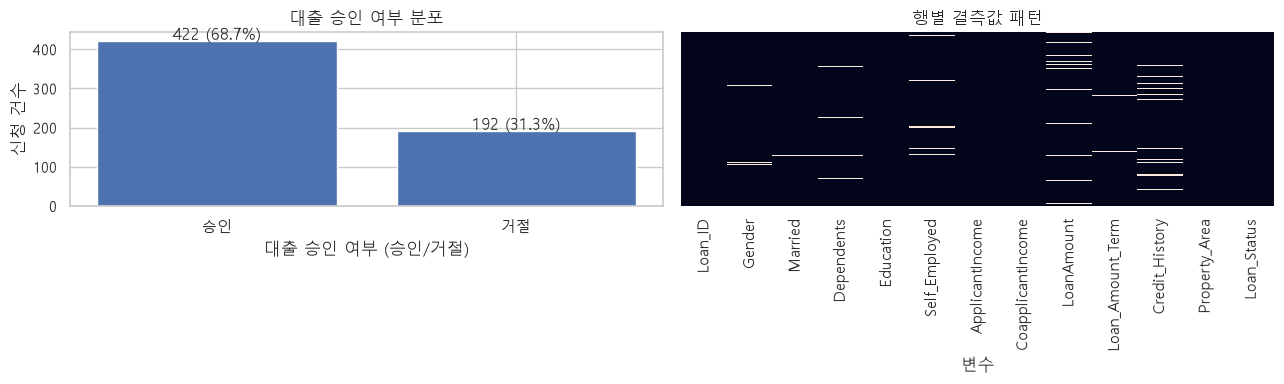

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
status_counts = df_raw["Loan_Status"].value_counts().reindex(["Y", "N"])
axes[0].bar(["승인", "거절"], status_counts.values)
axes[0].set_title("대출 승인 여부 분포")
axes[0].set_xlabel("대출 승인 여부 (승인/거절)")
axes[0].set_ylabel("신청 건수")
for i, v in enumerate(status_counts.values):
    axes[0].text(i, v + 2, f"{v} ({v/len(df_raw)*100:.1f}%)", ha="center")

sns.heatmap(df_raw.isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title("행별 결측값 패턴")
axes[1].set_xlabel("변수")
plt.tight_layout()
plt.show()

## 4. 탐색적 데이터 분석(EDA)
EDA는 데이터의 분포와 목표 변수의 관계를 탐색하는 단계다. 아래 결과는 상관관계나 연관성을 보여줄 뿐, 승인 여부의 원인이나 금융기관의 실제 심사 규칙을 증명하지 않는다.

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.46,6109.04,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.25,2926.25,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.41,85.59,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.00,65.12,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.84,0.36,0.0,1.0,1.0,1.00,1.0


,왜도
ApplicantIncome,6.54
CoapplicantIncome,7.49
LoanAmount,2.68
Loan_Amount_Term,-2.36
Credit_History,-1.88


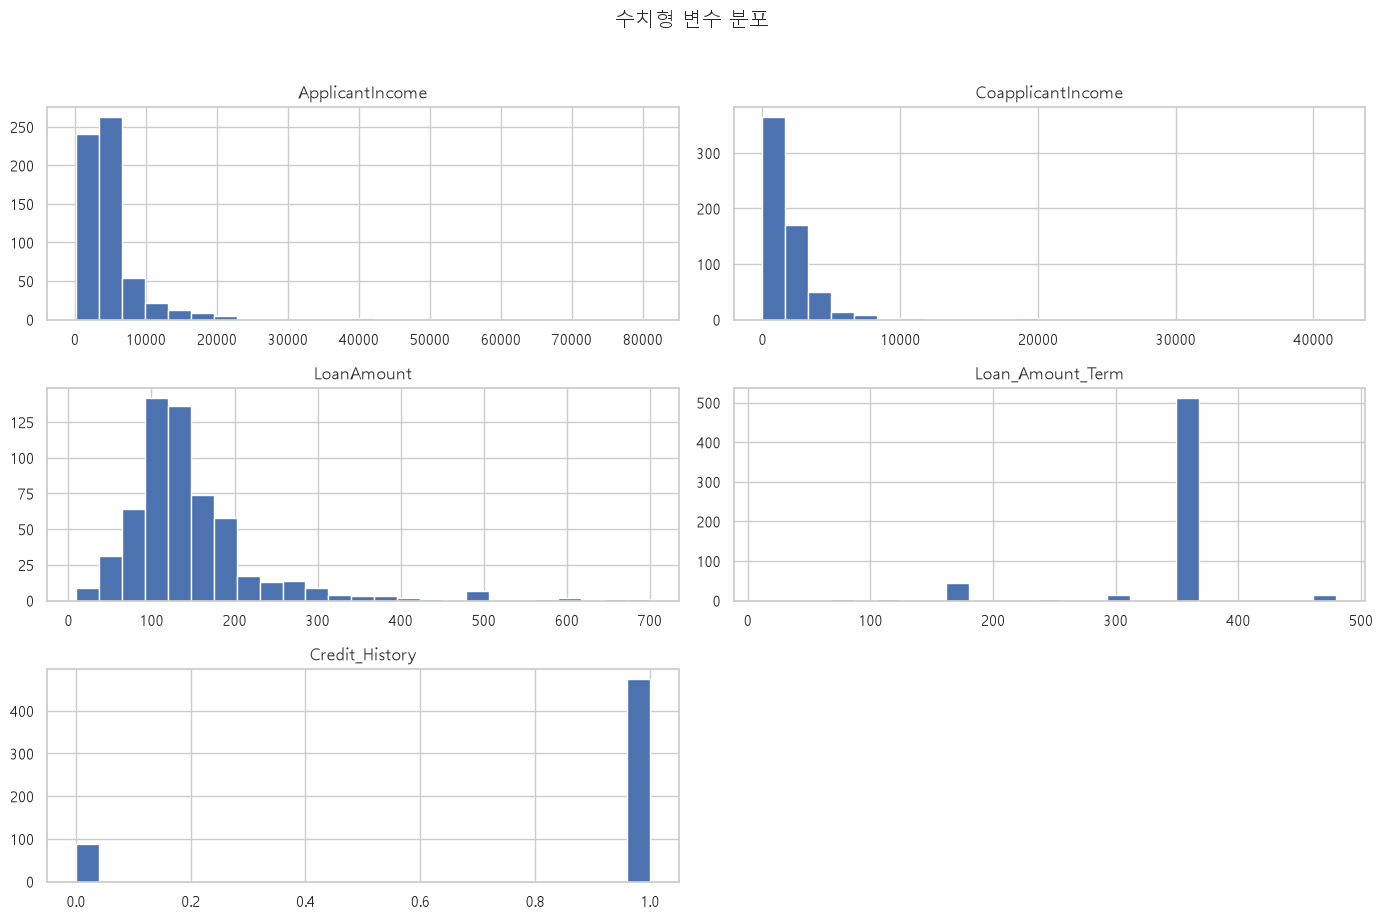

In [6]:
# 수치형 변수 분포: 왜도와 이상치 후보를 확인
numeric_cols_all = df_raw.select_dtypes(include=np.number).columns.tolist()
display(df_raw[numeric_cols_all].describe().T.round(2))
display(df_raw[numeric_cols_all].skew(numeric_only=True).rename("왜도").to_frame().round(2))

df_raw[numeric_cols_all].hist(figsize=(14, 9), bins=25, edgecolor="white")
plt.suptitle("수치형 변수 분포", y=1.02)
plt.tight_layout()
plt.show()

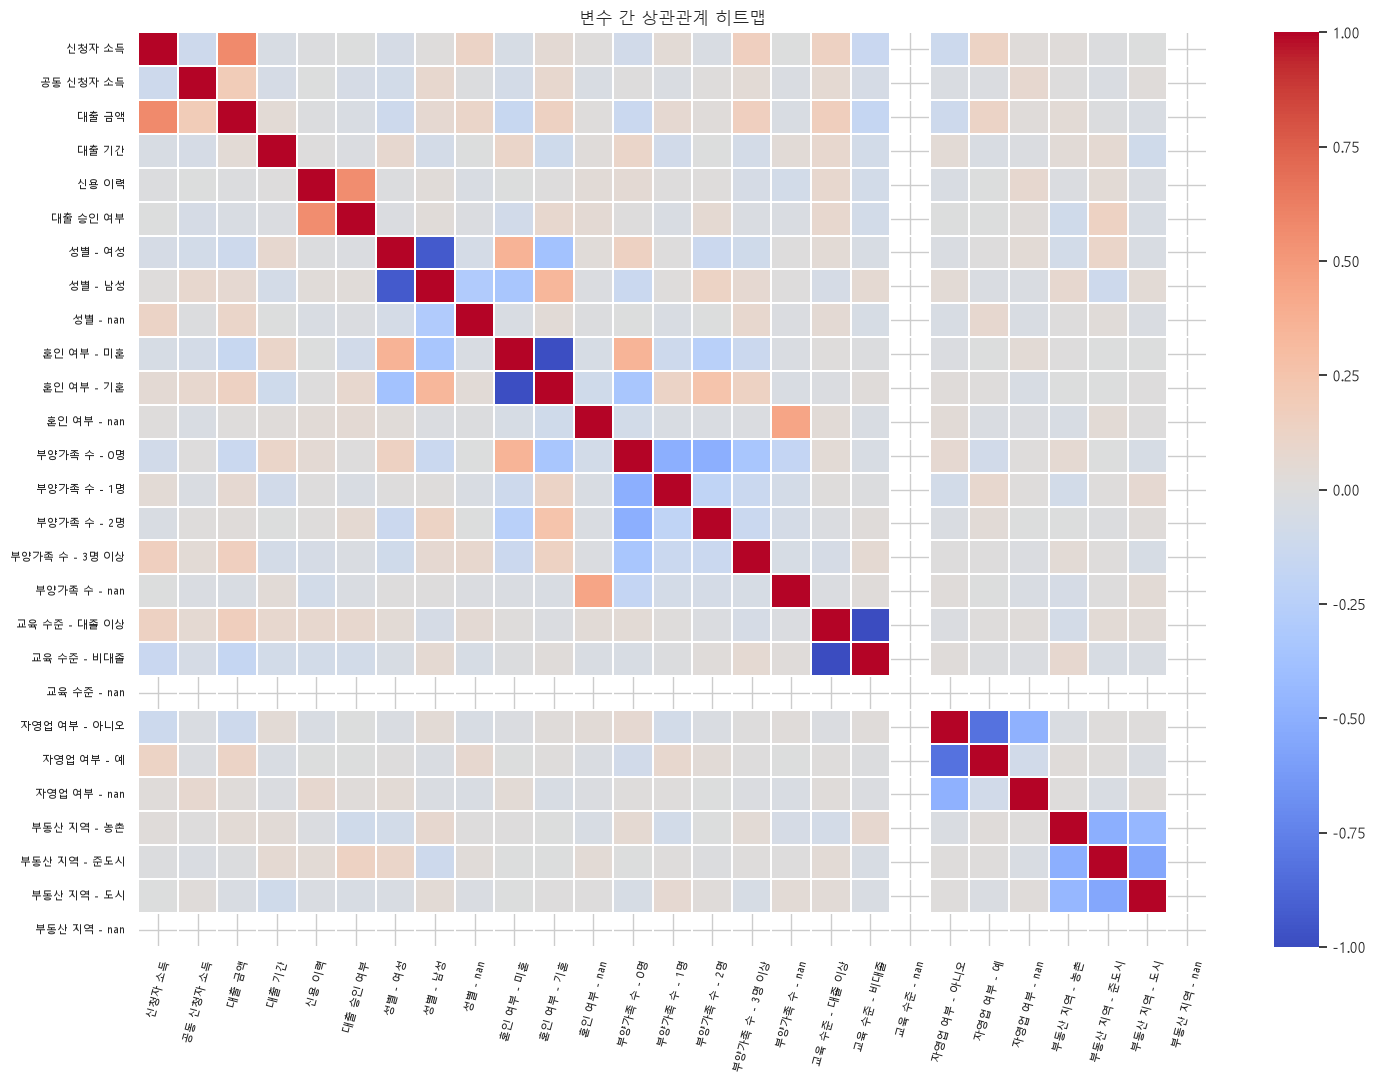

In [7]:
# 범주형 변수도 원-핫 인코딩해 변수 간 상관관계를 계산
# 승인 여부는 거절=0, 승인=1로 변환해 포함한다.
correlation_data = df_raw.drop(columns=["Loan_ID"], errors="ignore").copy()
correlation_data["Loan_Status"] = correlation_data["Loan_Status"].map({"N": 0, "Y": 1})
correlation_data = pd.get_dummies(correlation_data, dummy_na=True, dtype=float)
# 열 이름을 읽기 쉬운 한글로 표시
def korean_feature_name(name):
    for original, korean in FEATURE_LABELS.items():
        if name == original:
            return korean
        if name.startswith(original + "_"):
            suffix = name[len(original) + 1:]
            if original == "Loan_Status":
                suffix = {"0": "거절", "1": "승인"}.get(suffix, suffix)
            elif original == "Credit_History":
                suffix = {"0.0": "불량 또는 미확인", "1.0": "양호", "0": "불량 또는 미확인", "1": "양호"}.get(suffix, suffix)
            elif original == "Gender":
                suffix = {"Female": "여성", "Male": "남성"}.get(suffix, suffix)
            elif original == "Married":
                suffix = {"No": "미혼", "Yes": "기혼"}.get(suffix, suffix)
            elif original == "Education":
                suffix = {"Graduate": "대졸 이상", "Not Graduate": "비대졸"}.get(suffix, suffix)
            elif original == "Self_Employed":
                suffix = {"No": "아니오", "Yes": "예"}.get(suffix, suffix)
            elif original == "Property_Area":
                suffix = {"Rural": "농촌", "Semiurban": "준도시", "Urban": "도시"}.get(suffix, suffix)
            elif original == "Dependents":
                suffix = {"0": "0명", "1": "1명", "2": "2명", "3+": "3명 이상"}.get(suffix, suffix)
            return f"{korean} - {suffix}"
    return name
correlation_data.columns = [korean_feature_name(str(c)) for c in correlation_data.columns]
correlation_matrix = correlation_data.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(15, 11))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=False, linewidths=0.2, ax=ax)
ax.set_title("변수 간 상관관계 히트맵")
ax.tick_params(axis="x", labelrotation=75, labelsize=8)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()


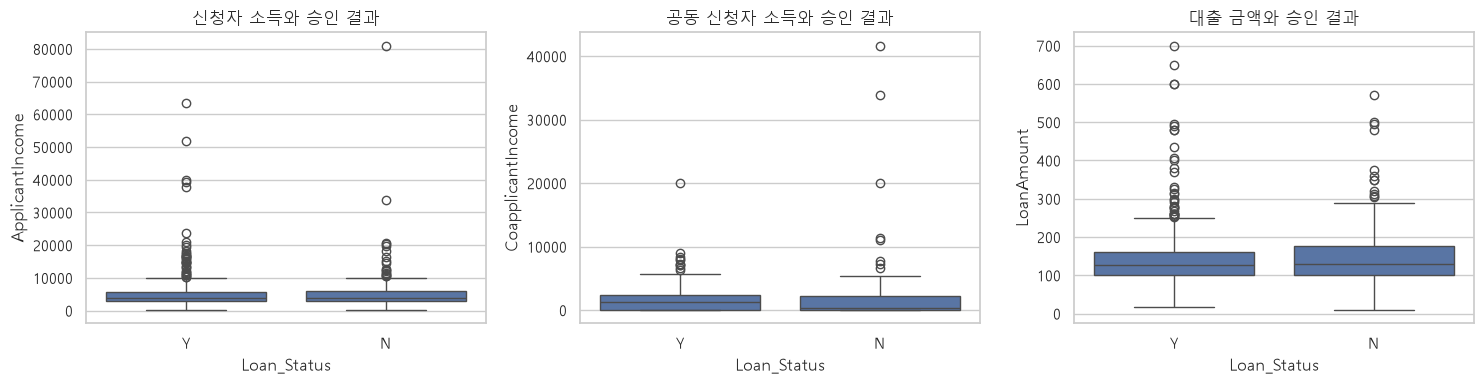

In [8]:
# 소득·대출금액 변수는 오른쪽 꼬리가 긴 분포인지 박스플롯으로 확인
plot_cols = [c for c in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"] if c in df_raw.columns]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(5 * len(plot_cols), 4))
if len(plot_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, plot_cols):
    sns.boxplot(data=df_raw, x="Loan_Status", y=col, ax=ax)
    ax.set_title(f"{FEATURE_LABELS.get(col, col)}와 승인 결과")
plt.tight_layout()
plt.show()

In [9]:
# 범주형 변수별 신청 건수와 승인 비율 표
categorical_cols = [c for c in df_raw.select_dtypes(exclude=np.number).columns if c not in ["Loan_ID", "Loan_Status"]]
approval_tables = []
for col in categorical_cols + ["Credit_History"]:
    temp = df_raw[[col, "Loan_Status"]].copy()
    temp[col] = temp[col].fillna("결측").astype(str)
    tab = temp.groupby(col, dropna=False)["Loan_Status"].agg(
        신청건수="size",
        승인건수=lambda s: (s == "Y").sum()
    )
    tab["승인비율(%)"] = (tab["승인건수"] / tab["신청건수"] * 100).round(2)
    tab.insert(0, "변수", col)
    tab = tab.reset_index().rename(columns={col: "범주"})
    tab["변수"] = FEATURE_LABELS.get(col, col)
    tab["범주"] = tab["범주"].astype(str).replace(CATEGORY_LABELS)
    approval_tables.append(tab)
approval_summary = pd.concat(approval_tables, ignore_index=True)
display(approval_summary.sort_values(["변수", "신청건수"], ascending=[True, False]))

,범주,변수,신청건수,승인건수,승인비율(%)
11,대졸 이상,교육 수준,480,340,70.83
12,비대졸,교육 수준,134,82,61.19
17,준도시,부동산 지역,233,179,76.82
18,도시,부동산 지역,202,133,65.84
16,농촌,부동산 지역,179,110,61.45
6,0명,부양가족 수,345,238,68.99
7,1명,부양가족 수,102,66,64.71
8,2명,부양가족 수,101,76,75.25
9,3명 이상,부양가족 수,51,33,64.71
10,결측,부양가족 수,15,9,60.00


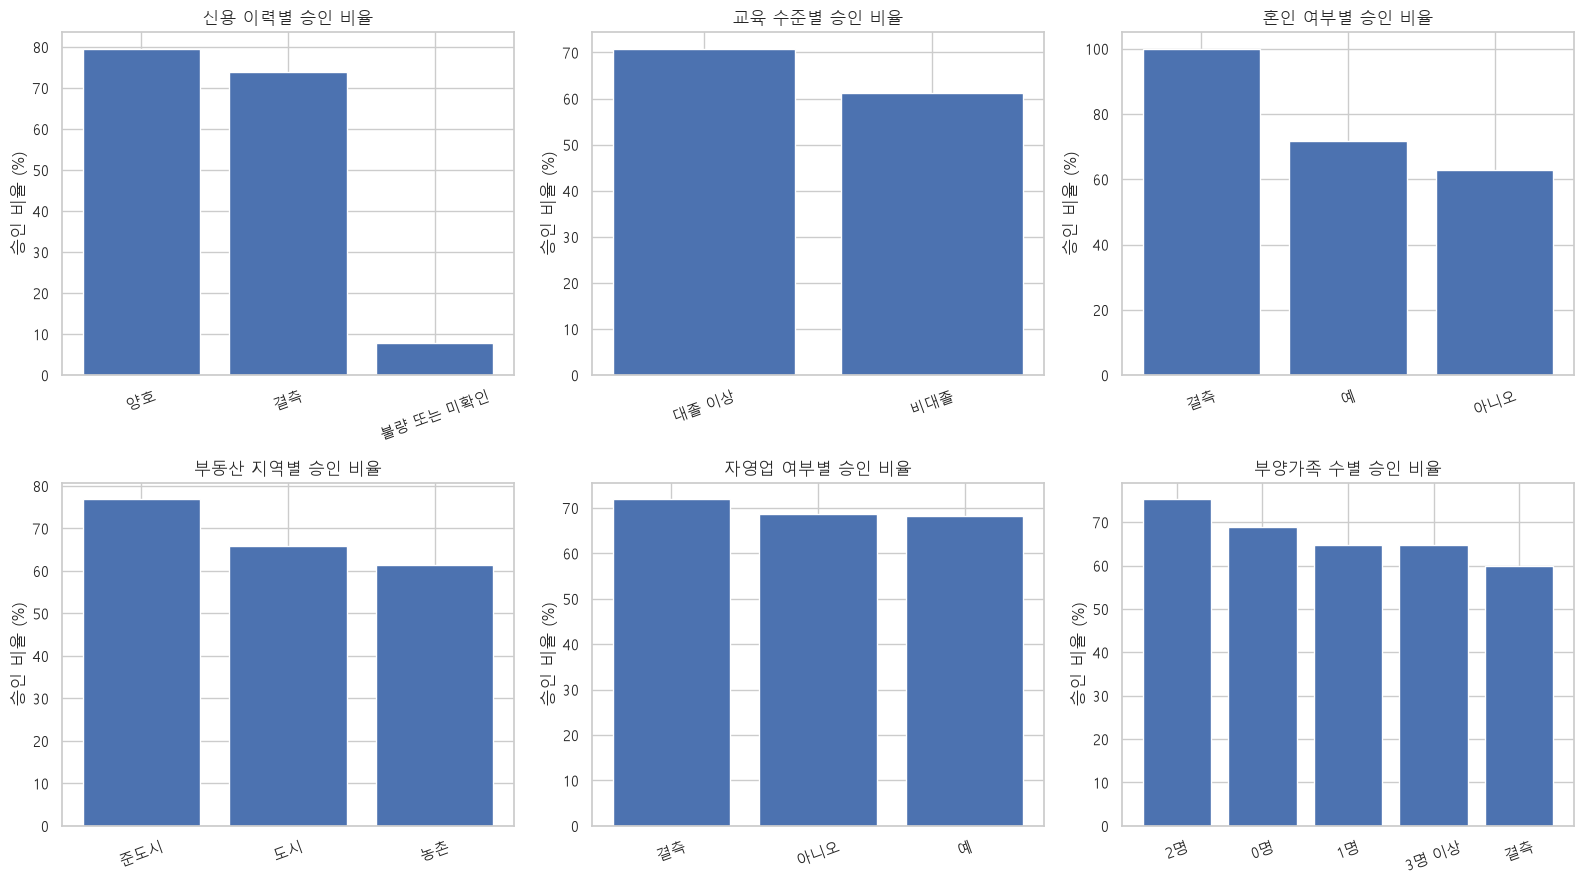

In [10]:
# 주요 범주형 변수별 승인 비율 시각화
eda_cat_cols = ["Credit_History", "Education", "Married", "Property_Area", "Self_Employed", "Dependents"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, eda_cat_cols):
    tmp = df_raw[[col, "Loan_Status"]].copy()
    tmp[col] = tmp[col].fillna("결측").astype(str)
    rates = tmp.groupby(col)["Loan_Status"].apply(lambda s: (s == "Y").mean() * 100).sort_values(ascending=False)
    ax.bar([CATEGORY_LABELS.get(str(v), str(v)) for v in rates.index], rates.values)
    ax.set_title(f"{FEATURE_LABELS.get(col, col)}별 승인 비율")
    ax.set_ylabel("승인 비율 (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 5. 전처리 설계 및 데이터 분리
- `Loan_ID`는 식별자이므로 예측 변수에서 제외한다.
- `Loan_Status`는 Y=1, N=0으로 변환한다.
- 수치형 결측치는 중앙값, 범주형 결측치는 최빈값으로 대체한다.
- 범주형 변수는 One-Hot Encoding으로 변환한다.
- 전처리 단계는 Pipeline 안에서 학습 데이터에만 적합시켜 테스트 데이터 정보가 전처리 단계에 누출되지 않도록 한다.
- 계층화 분할로 학습·테스트 데이터의 승인/거절 비율을 비슷하게 유지한다.

In [11]:
TARGET = "Loan_Status"
feature_columns = [c for c in df_raw.columns if c not in ["Loan_ID", TARGET]]
X = df_raw[feature_columns].copy()
y = df_raw[TARGET].map({"N": 0, "Y": 1})
if y.isna().any():
    raise ValueError("Loan_Status에 Y/N 이외의 값이 포함되어 있습니다.")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

split_summary = pd.DataFrame({
    "구분": ["전체", "학습", "테스트"],
    "건수": [len(X), int(len(X)*0.8), len(X)-int(len(X)*0.8)]
})
display(split_summary)
print("수치형 변수:", numeric_features)
print("범주형 변수:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"학습: {X_train.shape}, 테스트: {X_test.shape}")
print("학습 승인 비율:", round(y_train.mean()*100, 2), "%")
print("테스트 승인 비율:", round(y_test.mean()*100, 2), "%")

,구분,건수
0,전체,614
1,학습,491
2,테스트,123


수치형 변수: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
범주형 변수: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
학습: (491, 11), 테스트: (123, 11)
학습 승인 비율: 68.64 %
테스트 승인 비율: 69.11 %


In [12]:
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

## 6. 기준 모델과 후보 모델 비교
단일 모델만 학습하면 알고리즘 선택이 타당한지 판단하기 어렵다. DummyClassifier를 기준선으로 포함하고, Logistic Regression, Decision Tree, Random Forest, Extra Trees를 동일한 5-fold Stratified Cross-Validation으로 비교한다. 비교는 학습 데이터에서만 수행하고, 최종 테스트 데이터는 마지막 평가에 사용한다.

In [13]:
models = {
    "기준 모델": DummyClassifier(strategy="most_frequent"),
    "로지스틱 회귀": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "의사결정나무": DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=5, random_state=RANDOM_STATE),
    "랜덤 포레스트": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    "엑스트라 트리": ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
comparison_rows = []
candidate_pipelines = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
    candidate_pipelines[name] = pipe
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise")
    comparison_rows.append({
        "모델": name,
        "CV Accuracy 평균": scores["test_accuracy"].mean(),
        "CV Precision 평균": scores["test_precision"].mean(),
        "CV Recall 평균": scores["test_recall"].mean(),
        "CV F1 평균": scores["test_f1"].mean(),
        "CV ROC-AUC 평균": scores["test_roc_auc"].mean(),
        "CV F1 표준편차": scores["test_f1"].std()
    })
comparison_df = pd.DataFrame(comparison_rows).sort_values("CV F1 평균", ascending=False).reset_index(drop=True)
display(comparison_df.rename(columns={"모델": "모델명", "CV Accuracy 평균": "교차 검증 정확도 평균", "CV Precision 평균": "교차 검증 정밀도 평균", "CV Recall 평균": "교차 검증 재현율 평균", "CV F1 평균": "교차 검증 F1 평균", "CV ROC-AUC 평균": "교차 검증 ROC-AUC 평균", "CV F1 표준편차": "교차 검증 F1 표준편차"}).round(4))

,모델명,교차 검증 정확도 평균,교차 검증 정밀도 평균,교차 검증 재현율 평균,교차 검증 F1 평균,교차 검증 ROC-AUC 평균,교차 검증 F1 표준편차
0,랜덤 포레스트,0.7475,0.7963,0.8521,0.8217,0.7495,0.0388
1,기준 모델,0.6864,0.6864,1.0000,0.8140,0.5000,0.0028
2,로지스틱 회귀,0.7290,0.7934,0.8222,0.8058,0.7263,0.0343
3,엑스트라 트리,0.7128,0.7728,0.8253,0.7973,0.7027,0.0293
4,의사결정나무,0.6170,0.7611,0.6468,0.6989,0.6564,0.0283


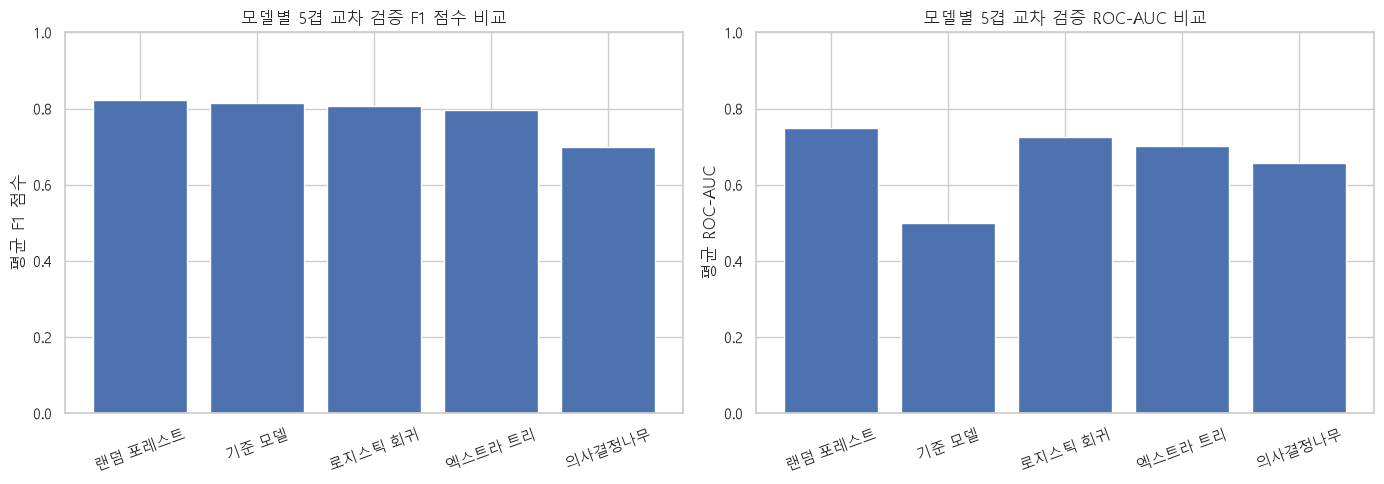

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(comparison_df["모델"], comparison_df["CV F1 평균"])
axes[0].set_ylim(0, 1)
axes[0].set_title("모델별 5겹 교차 검증 F1 점수 비교")
axes[0].set_ylabel("평균 F1 점수")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(comparison_df["모델"], comparison_df["CV ROC-AUC 평균"])
axes[1].set_ylim(0, 1)
axes[1].set_title("모델별 5겹 교차 검증 ROC-AUC 비교")
axes[1].set_ylabel("평균 ROC-AUC")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. 모델 선택 및 테스트 데이터 평가
이 예제에서는 교차검증 F1 평균을 기본 선택 기준으로 사용한다. F1은 정밀도와 재현율을 함께 고려하지만, 실제 금융 문제에서는 거절을 승인으로 분류하는 오류와 승인을 거절로 분류하는 오류의 비용이 다를 수 있으므로 업무 목적에 맞는 지표 선택이 필요하다.

In [15]:
best_name = comparison_df.iloc[0]["모델"]
best_model = candidate_pipelines[best_name]
best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, list(best_model.named_steps["classifier"].classes_).index(1)]
test_metrics = {
    "정확도": float(accuracy_score(y_test, y_pred)),
    "정밀도": float(precision_score(y_test, y_pred, zero_division=0)),
    "재현율": float(recall_score(y_test, y_pred, zero_division=0)),
    "F1 점수": float(f1_score(y_test, y_pred, zero_division=0)),
    "ROC-AUC": float(roc_auc_score(y_test, y_prob))
}
print("선택 모델:", best_name)
display(pd.DataFrame([test_metrics]).T.rename(columns={0:"테스트 점수"}).round(4))
report_dict = classification_report(y_test, y_pred, target_names=["거절", "승인"], zero_division=0, output_dict=True)
report_df = pd.DataFrame(report_dict).T.rename(columns={"precision": "정밀도", "recall": "재현율", "f1-score": "F1 점수", "support": "표본 수"})
report_df.index = report_df.index.map(lambda i: {"accuracy": "정확도", "macro avg": "단순 평균", "weighted avg": "가중 평균"}.get(i, i))
display(report_df.round(3))

선택 모델: 랜덤 포레스트


,테스트 점수
정확도,0.8130
정밀도,0.8605
재현율,0.8706
F1 점수,0.8655
ROC-AUC,0.7966


,정밀도,재현율,F1 점수,표본 수
거절,0.703,0.684,0.693,38.000
승인,0.860,0.871,0.865,85.000
정확도,0.813,0.813,0.813,0.813
단순 평균,0.782,0.777,0.779,123.000
가중 평균,0.812,0.813,0.812,123.000


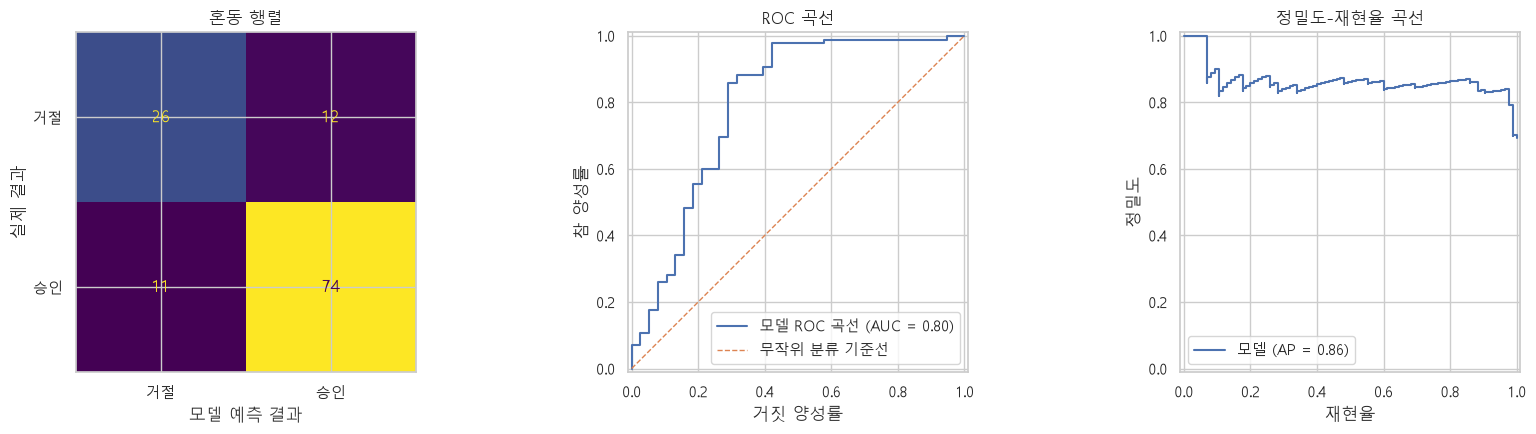

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["거절", "승인"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("혼동 행렬")
axes[0].set_xlabel("모델 예측 결과")
axes[0].set_ylabel("실제 결과")
roc_display = RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1], name="모델 ROC 곡선")
roc_curve_data = {"fpr": roc_display.fpr.tolist(), "tpr": roc_display.tpr.tolist()}
axes[1].plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="무작위 분류 기준선")
axes[1].set_title("ROC 곡선")
axes[1].set_xlabel("거짓 양성률")
axes[1].set_ylabel("참 양성률")
axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2], name="모델")
axes[2].set_title("정밀도-재현율 곡선")
axes[2].set_xlabel("재현율")
axes[2].set_ylabel("정밀도")
plt.tight_layout()
plt.show()


## 8. 변수 중요도 및 결과 해석
Permutation Importance는 테스트 데이터의 한 변수 값을 무작위로 섞었을 때 F1 점수가 얼마나 감소하는지 측정한다. 값이 클수록 해당 모델에서 예측에 유용한 정보였다는 뜻이며, 인과적 영향력이나 공정성을 뜻하지 않는다.

,feature,importance_mean,importance_std
9,Credit_History,0.1499,0.0239
10,Property_Area,0.0295,0.0161
6,CoapplicantIncome,0.0231,0.0132
2,Dependents,0.0114,0.0127
1,Married,0.0099,0.0107
7,LoanAmount,0.0097,0.0117
0,Gender,0.0064,0.0036
5,ApplicantIncome,0.0051,0.0155
4,Self_Employed,0.0025,0.0058
8,Loan_Amount_Term,0.0023,0.0047


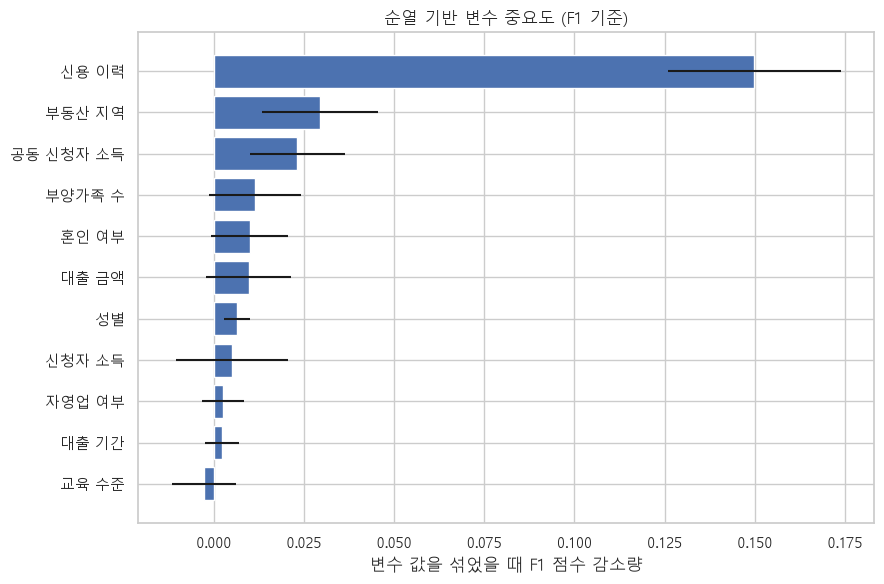

In [17]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=20, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance_df.round(4))
top_imp = importance_df.sort_values("importance_mean").tail(12)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_imp["feature"].map(lambda x: FEATURE_LABELS.get(x, x)), top_imp["importance_mean"], xerr=top_imp["importance_std"])
ax.set_title("순열 기반 변수 중요도 (F1 기준)")
ax.set_xlabel("변수 값을 섞었을 때 F1 점수 감소량")
plt.tight_layout()
plt.show()

## 9. 보고서용 결과 요약표 생성

In [18]:
report_summary = pd.DataFrame([
    ["데이터 크기", f"{df_raw.shape[0]}행 × {df_raw.shape[1]}열"],
    ["결측 셀 수", int(df_raw.isna().sum().sum())],
    ["승인 비율", f"{(y.mean()*100):.2f}%"],
    ["선택 모델", best_name],
    ["모델 선택 기준", "5겹 교차 검증 F1 평균"],
    ["학습/테스트 분할", "80% / 20%, 계층화 분할 적용"],
    ["전처리", "수치형 중앙값 대체 및 표준화, 범주형 최빈값 대체 및 원-핫 인코딩"],
    ["테스트 정확도", f"{test_metrics['정확도']:.4f}"],
    ["테스트 정밀도", f"{test_metrics['정밀도']:.4f}"],
    ["테스트 재현율", f"{test_metrics['재현율']:.4f}"],
    ["테스트 F1 점수", f"{test_metrics['F1 점수']:.4f}"],
    ["테스트 ROC-AUC", f"{test_metrics['ROC-AUC']:.4f}"],
], columns=["항목", "결과"])
display(report_summary)


,항목,결과
0,데이터 크기,614행 × 13열
1,결측 셀 수,149
2,승인 비율,68.73%
3,선택 모델,랜덤 포레스트
4,모델 선택 기준,5겹 교차 검증 F1 평균
5,학습/테스트 분할,"80% / 20%, 계층화 분할 적용"
6,전처리,"수치형 중앙값 대체 및 표준화, 범주형 최빈값 대체 및 원-핫 인코딩"
7,테스트 정확도,0.8130
8,테스트 정밀도,0.8605
9,테스트 재현율,0.8706


## 10. 모델 및 메타데이터 저장
저장되는 모델은 전처리기와 분류기를 함께 포함한 Pipeline이다. 따라서 Streamlit 앱에서는 입력 데이터에 동일한 전처리를 별도로 구현할 필요가 없다.

In [19]:
joblib.dump(best_model, MODEL_DIR / "model.pkl")
meta = {
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "selected_model": best_name,
    "metrics": test_metrics,
    "model_comparison": comparison_df.round(6).to_dict(orient="records"),
    "confusion_matrix": cm.tolist(),
    "roc_curve": roc_curve_data,
    "permutation_importance": importance_df.round(6).to_dict(orient="records"),
    "target_mapping": {"N": 0, "Y": 1},
    "random_state": RANDOM_STATE,
    "test_size": 0.2
}
joblib.dump(meta, MODEL_DIR / "model_meta.joblib")
print("저장 완료:")
print(MODEL_DIR / "model.pkl")
print(MODEL_DIR / "model_meta.joblib")

저장 완료:
c:\Users\human-03\Desktop\오미나_머신러닝\model\model.pkl
c:\Users\human-03\Desktop\오미나_머신러닝\model\model_meta.joblib
